In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from src.config import (
    BATCH_SIZE,
    IMG_SIZE,
    SPLIT_MANIFEST_PATH,
    CLASSES
)

from src.preprocessing import dataset_from_manifest

print("TensorFlow:", tf.__version__)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

I0000 00:00:1792008743.191884    9280 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792008743.195662    9280 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792008743.511557    9280 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792008745.759403    9280 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow: 2.21.0
Tamaño de imagen: (128, 128)
Batch size: 8


# 1.Cargar el manifiesto

In [2]:
split = pd.read_csv(
    SPLIT_MANIFEST_PATH
)

print("Total de imágenes:", len(split))

print("\nDistribución:")
print(
    split.groupby(
        ["split", "label_name"]
    ).size()
)

Total de imágenes: 975

Distribución:
split  label_name
test   OverRipe        5
       Ripe            8
       UnRipe        139
train  OverRipe       14
       Ripe           29
       UnRipe        636
val    OverRipe        2
       Ripe            6
       UnRipe        136
dtype: int64


# 2.Crear los datasets

In [3]:
train_ds = dataset_from_manifest(
    split,
    "train",
    batch_size=BATCH_SIZE,
    augment=True
)

val_ds = dataset_from_manifest(
    split,
    "val",
    batch_size=BATCH_SIZE,
    augment=False
)

test_ds = dataset_from_manifest(
    split,
    "test",
    batch_size=BATCH_SIZE,
    augment=False
)

E0000 00:00:1792008747.082195    9280 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


# 3.Verificar el batch

In [4]:
for x, y in train_ds.take(1):

    print("Shape de imágenes:", x.shape)
    print("Shape de labels:", y.shape)

    print("Tipo:", x.dtype)

    print(
        "Valor mínimo:",
        float(tf.reduce_min(x))
    )

    print(
        "Valor máximo:",
        float(tf.reduce_max(x))
    )

    print(
        "Labels:",
        y.numpy()
    )

Shape de imágenes: (8, 128, 128, 3)
Shape de labels: (8,)
Tipo: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0
Labels: [2 2 2 2 2 2 2 2]


# 4.Ver las imágenes

In [5]:
class_names = {
    0: "OverRipe",
    1: "Ripe",
    2: "UnRipe"
}

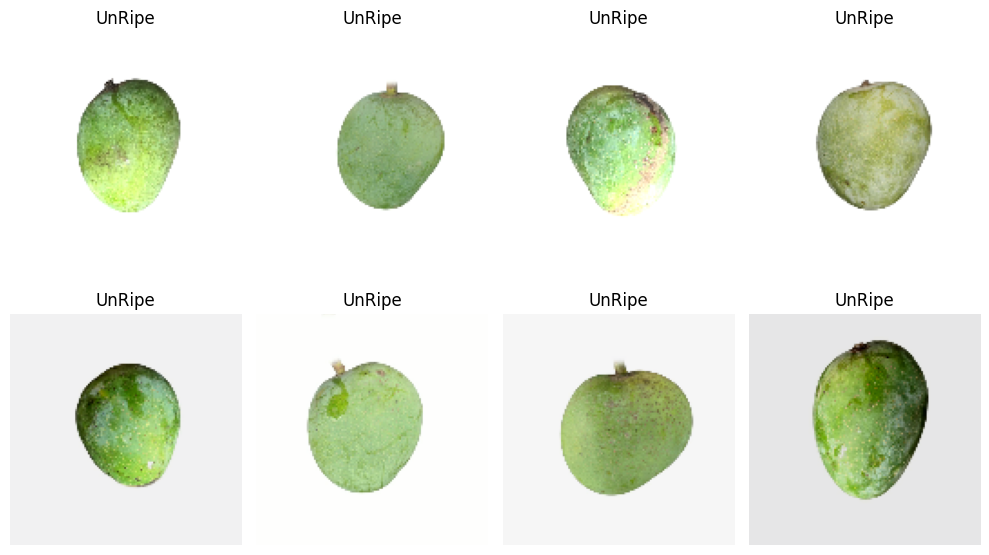

In [6]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 6))

for i in range(min(8, len(images))):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    plt.title(
        class_names[int(labels[i].numpy())]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# 5.Comprobar tamaños

In [7]:
print("Tamaño configurado:", IMG_SIZE)

for images, labels in train_ds.take(1):
    print("Tamaño real del batch:", images.shape)

Tamaño configurado: (128, 128)
Tamaño real del batch: (8, 128, 128, 3)
